# ShopSage — exploratory data analysis

UCI Online Retail II after cleaning (`make data`). Figures are also saved to `docs/figures/`. The five findings at the end are generated from the numbers computed here.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown

from shopsage.config import DUCKDB_PATH, ROOT

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(DUCKDB_PATH), read_only=True)
q = lambda sql: con.execute(sql).df()
F = {}  # facts used in the findings
q("SELECT count(*) AS lines, count(DISTINCT customer_id) AS customers, count(DISTINCT stock_code) AS items, "
  "count(DISTINCT invoice) AS orders, min(invoice_date) AS first, max(invoice_date) AS last FROM transactions")

,lines,customers,items,orders,first,last
0,770338,5839,4611,36325,2009-12-01 07:45:00,2011-12-09 12:50:00


## 1. Sales over time

,month,revenue,orders,customers,m
18,2011-06-01,690009.68,1511,986,6
19,2011-07-01,681847.47,1445,945,7
20,2011-08-01,715177.01,1336,933,8
21,2011-09-01,1017557.36,1807,1254,9
22,2011-10-01,1070933.31,1986,1356,10
23,2011-11-01,1439128.99,2740,1657,11


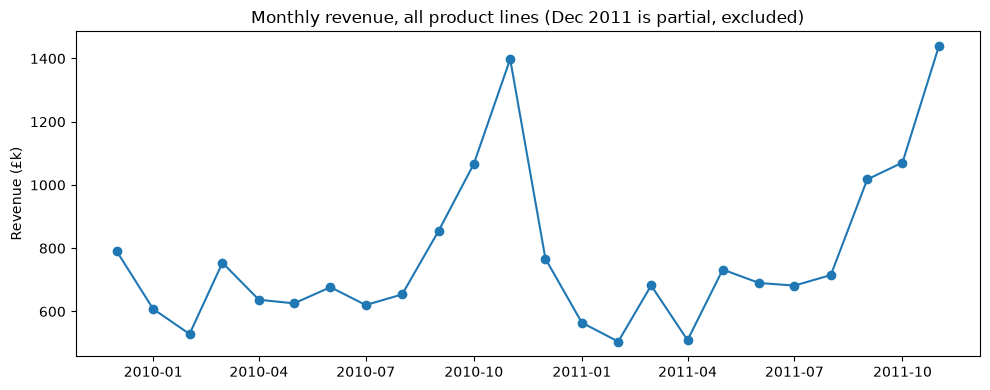

In [2]:
monthly = q("""
SELECT date_trunc('month', invoice_date) AS month, sum(revenue) AS revenue,
       count(DISTINCT invoice) AS orders, count(DISTINCT customer_id) AS customers
FROM lines_all WHERE invoice_date < '2011-12-01' GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.month, monthly.revenue / 1e3, marker="o")
ax.set_ylabel("Revenue (£k)"); ax.set_title("Monthly revenue, all product lines (Dec 2011 is partial, excluded)")
fig.tight_layout(); fig.savefig(FIG / "monthly_revenue.png", dpi=120)
monthly["m"] = monthly.month.dt.month
by_m = monthly.groupby("m").revenue.mean()
F["peak_month"] = monthly.loc[monthly.revenue.idxmax(), "month"].strftime("%B %Y")
F["q4_share"] = monthly.loc[monthly.m.isin([9, 10, 11]), "revenue"].sum() / monthly.revenue.sum()
F["nov_vs_feb"] = by_m[11] / by_m[2]
monthly.tail(6)

## 2. Basket sizes

,items,value
count,36325.000000,36325.000000
mean,20.921569,453.133452
std,22.367004,913.561239
min,1.000000,0.380000
25%,7.000000,157.900000
50%,15.000000,301.290000
75%,27.000000,470.150000
max,540.000000,43627.600000


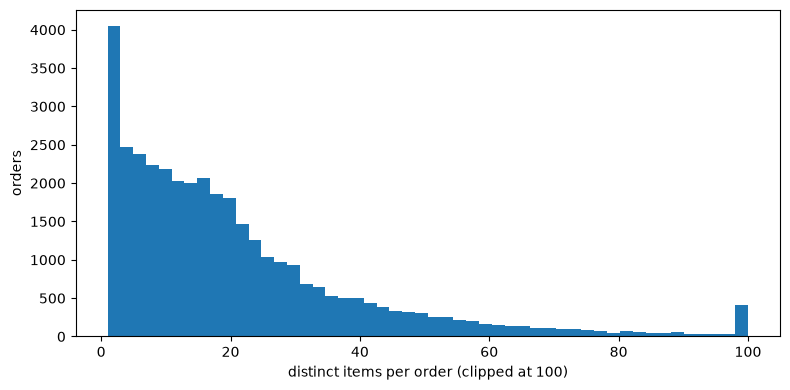

In [3]:
baskets = q("""SELECT invoice, count(DISTINCT stock_code) AS items, sum(revenue) AS value
FROM transactions GROUP BY 1""")
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(baskets["items"].clip(upper=100), bins=50)
ax.set_xlabel("distinct items per order (clipped at 100)"); ax.set_ylabel("orders")
fig.tight_layout(); fig.savefig(FIG / "basket_sizes.png", dpi=120)
F["basket_median"] = baskets["items"].median()
F["basket_mean"] = baskets["items"].mean()
F["basket_single_share"] = (baskets["items"] == 1).mean()
baskets.describe()

## 3. Item popularity — the long tail

,stock_code,buyers,lines,description
0,85123A,1484,4989,WHITE HANGING HEART T-LIGHT HOLDER
1,85099B,975,3279,JUMBO BAG RED RETROSPOT
2,22423,1299,3219,REGENCY CAKESTAND 3 TIER
3,84879,1007,2685,ASSORTED COLOUR BIRD ORNAMENT
4,20725,842,2591,LUNCH BAG RED RETROSPOT
5,21212,1111,2544,PACK OF 72 RETROSPOT CAKE CASES
6,47566,894,2086,PARTY BUNTING
7,20727,704,2034,LUNCH BAG BLACK SKULL.
8,22383,660,2029,LUNCH BAG SUKI DESIGN
9,21034,799,1945,REX CASH+CARRY JUMBO SHOPPER


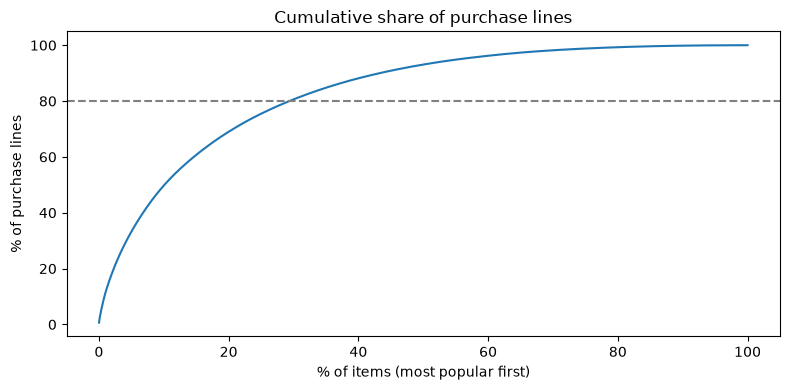

In [4]:
pop = q("""SELECT stock_code, count(DISTINCT customer_id) AS buyers, count(*) AS lines
FROM transactions GROUP BY 1 ORDER BY lines DESC""")
cum = pop["lines"].cumsum() / pop["lines"].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(pop) + 1) / len(pop) * 100, cum * 100)
ax.set_xlabel("% of items (most popular first)"); ax.set_ylabel("% of purchase lines")
ax.axhline(80, ls="--", c="grey"); ax.set_title("Cumulative share of purchase lines")
fig.tight_layout(); fig.savefig(FIG / "long_tail.png", dpi=120)
F["items_for_80pct"] = (cum < 0.8).sum() + 1
F["items_total"] = len(pop)
F["items_le5_buyers"] = (pop.buyers <= 5).mean()
pop.head(10).merge(q("SELECT stock_code, description FROM products"), on="stock_code")

## 4. Countries

,country,customers,revenue,revenue_share
0,United Kingdom,5326,1.374709e+07,0.835178
1,EIRE,3,5.695060e+05,0.034599
2,Netherlands,22,5.462625e+05,0.033187
3,Germany,107,3.799772e+05,0.023085
4,France,93,2.943470e+05,0.017882
5,Australia,15,1.667344e+05,0.010130
6,Switzerland,22,9.269996e+04,0.005632
7,Spain,38,8.509283e+04,0.005170
8,Sweden,19,8.424974e+04,0.005118
9,Denmark,12,6.347819e+04,0.003856


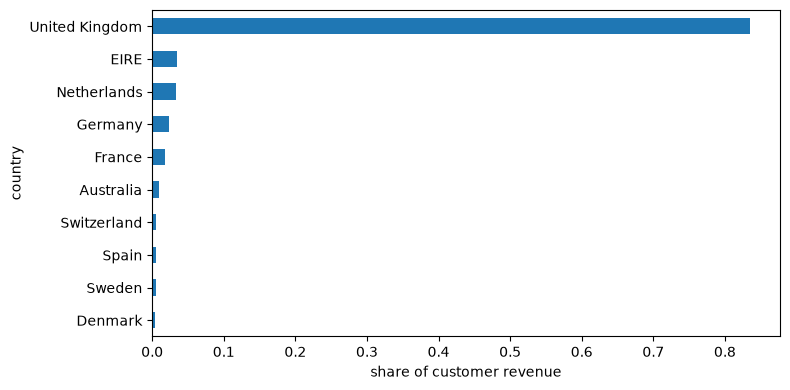

In [5]:
ctry = q("""SELECT country, count(DISTINCT customer_id) AS customers, sum(revenue) AS revenue
FROM transactions GROUP BY 1 ORDER BY revenue DESC""")
ctry["revenue_share"] = ctry.revenue / ctry.revenue.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ctry.head(10).plot.barh(x="country", y="revenue_share", ax=ax, legend=False)
ax.invert_yaxis(); ax.set_xlabel("share of customer revenue")
fig.tight_layout(); fig.savefig(FIG / "countries.png", dpi=120)
F["uk_rev_share"] = ctry.set_index("country").loc["United Kingdom", "revenue_share"]
F["uk_cust_share"] = ctry.set_index("country").loc["United Kingdom", "customers"] / ctry.customers.sum()
F["n_countries"] = len(ctry)
ctry.head(10)

## 5. Repeat purchases

count    5839.000000
mean        6.221100
std        12.633796
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       369.000000
Name: orders, dtype: float64

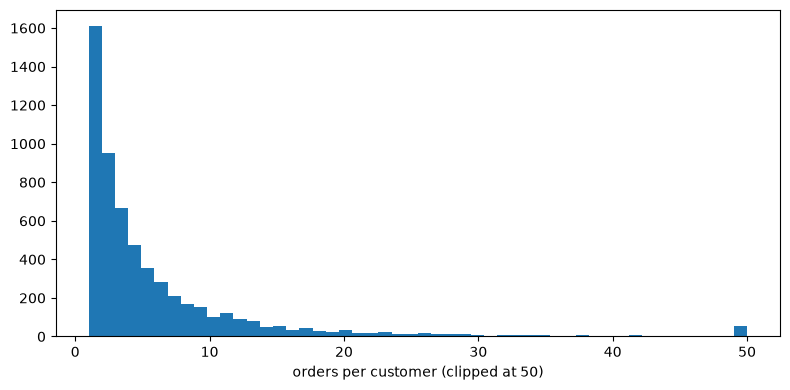

In [6]:
cust = q("""SELECT customer_id, count(DISTINCT invoice) AS orders, sum(revenue) AS revenue
FROM transactions GROUP BY 1""")
F["repeat_share"] = (cust.orders > 1).mean()
top = cust.sort_values("revenue", ascending=False)
F["top10pct_rev_share"] = top.revenue.head(len(top) // 10).sum() / top.revenue.sum()
gaps = q("""WITH o AS (SELECT DISTINCT customer_id, invoice, min(invoice_date) OVER (PARTITION BY invoice) AS d
                   FROM transactions),
             g AS (SELECT customer_id, date_diff('day', lag(d) OVER (PARTITION BY customer_id ORDER BY d), d) AS gap FROM
                   (SELECT DISTINCT customer_id, invoice, d FROM o))
        SELECT gap FROM g WHERE gap IS NOT NULL""")
F["median_gap_days"] = gaps.gap.median()
rebuy = q("""SELECT avg(CASE WHEN n > 1 THEN 1 ELSE 0 END) AS share FROM
              (SELECT customer_id, stock_code, count(DISTINCT invoice) AS n FROM transactions GROUP BY 1, 2)""")
F["pair_rebuy_share"] = rebuy.share[0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cust.orders.clip(upper=50), bins=50); ax.set_xlabel("orders per customer (clipped at 50)")
fig.tight_layout(); fig.savefig(FIG / "orders_per_customer.png", dpi=120)
cust.orders.describe()

## 6. Sparsity of the customer × item matrix

In [7]:
s = q("SELECT count(DISTINCT customer_id) AS u, count(DISTINCT stock_code) AS i, "
      "count(DISTINCT (customer_id, stock_code)) AS nnz FROM transactions")
F["density"] = s.nnz[0] / (s.u[0] * s.i[0])
F["nnz"] = s.nnz[0]
s.assign(density=F["density"])

,u,i,nnz,density
0,5839,4611,478044,0.017756


## Five findings

In [8]:
Markdown(f"""
1. **Strong Q4 seasonality.** September–November make up {F['q4_share']:.0%} of revenue over the
   two years, the peak month is {F['peak_month']}, and an average November sells {F['nov_vs_feb']:.1f}× an
   average February. A test window of Sep–Nov 2011 is therefore the busiest, most gift-driven period.
2. **Large, wholesale-like baskets.** The median order has {F['basket_median']:.0f} distinct items
   (mean {F['basket_mean']:.1f}); only {F['basket_single_share']:.0%} of orders are single-item. Many
   customers are small retailers buying in bulk, so co-purchase signals are rich.
3. **A long tail.** {F['items_for_80pct']:,} of {F['items_total']:,} items
   ({F['items_for_80pct']/F['items_total']:.0%}) account for 80% of purchase lines, and
   {F['items_le5_buyers']:.0%} of items have five or fewer buyers. Popularity baselines may be hard to beat
   on accuracy but give poor coverage.
4. **UK-centric.** The UK is {F['uk_cust_share']:.0%} of customers and {F['uk_rev_share']:.0%} of customer
   revenue across {F['n_countries']} countries.
5. **Loyal repeat buyers who re-buy the same things.** {F['repeat_share']:.0%} of customers ordered more
   than once (median gap between orders {F['median_gap_days']:.0f} days); the top 10% of customers bring
   {F['top10pct_rev_share']:.0%} of revenue; and {F['pair_rebuy_share']:.0%} of customer–item pairs were
   bought in more than one order. A "buy again" baseline is likely to be strong. The interaction matrix has
   {F['nnz']:,} non-zeros, a density of only {F['density']:.2%}.
""")


1. **Strong Q4 seasonality.** September–November make up 37% of revenue over the
   two years, the peak month is November 2011, and an average November sells 2.7× an
   average February. A test window of Sep–Nov 2011 is therefore the busiest, most gift-driven period.
2. **Large, wholesale-like baskets.** The median order has 15 distinct items
   (mean 20.9); only 7% of orders are single-item. Many
   customers are small retailers buying in bulk, so co-purchase signals are rich.
3. **A long tail.** 1,355 of 4,611 items
   (29%) account for 80% of purchase lines, and
   11% of items have five or fewer buyers. Popularity baselines may be hard to beat
   on accuracy but give poor coverage.
4. **UK-centric.** The UK is 91% of customers and 84% of customer
   revenue across 41 countries.
5. **Loyal repeat buyers who re-buy the same things.** 72% of customers ordered more
   than once (median gap between orders 25 days); the top 10% of customers bring
   63% of revenue; and 25% of customer–item pairs were
   bought in more than one order. A "buy again" baseline is likely to be strong. The interaction matrix has
   478,044 non-zeros, a density of only 1.78%.
